In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [23]:
CSV_FILE = "student_performance.csv"
df = pd.read_csv(CSV_FILE)
print("FIRST 5 ROWS")
print(df.head())


FIRST 5 ROWS
   student_id  gender    department  study_hours  attendance  midterm  final  \
0        1001  Female            SE          5.9        80.7     71.4   62.1   
1        1002  Female            CS          4.7        86.6     62.1   75.7   
2        1003  Female  Data Science          1.3        77.7     54.6   52.7   
3        1004    Male            SE          6.9        83.3     70.0   80.6   
4        1005  Female            IT          3.8        81.9     61.6   79.3   

   total result  
0   65.8   Pass  
1   70.3   Pass  
2   53.5   Pass  
3   76.4   Pass  
4   72.2   Pass  


In [24]:
print("\n SHAPE ", df.shape)


 SHAPE  (300, 9)


In [25]:
print("\nDATA TYPES")
print(df.dtypes)


DATA TYPES
student_id       int64
gender             str
department         str
study_hours    float64
attendance     float64
midterm        float64
final          float64
total          float64
result             str
dtype: object


In [29]:
# 2. Data cleaning
# ------------------------------------------------------------------
print("\n=== MISSING VALUES (before cleaning) ===")
print(df.isnull().sum()[df.isnull().sum() > 0])

num_cols = df.select_dtypes(include="number").columns.drop("student_id", errors="ignore")
cat_cols = df.select_dtypes(exclude="number").columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())   # fill with median
df = df.drop_duplicates()
print("Missing values after cleaning:", df.isnull().sum().sum())


=== MISSING VALUES (before cleaning) ===
study_hours    4
attendance     6
dtype: int64
Missing values after cleaning: 0


In [26]:
print("\nSUMMARY STATISTICS (numeric) ")
summary = df[num_cols].describe().round(2)
print(summary)


SUMMARY STATISTICS (numeric) 
       study_hours  attendance  midterm   final   total
count       296.00      294.00   300.00  300.00  300.00
mean          4.83       79.70    65.03   66.52   65.93
std           2.01       11.48    11.28   12.99   10.74
min           0.50       40.00    30.50   33.10   33.60
25%           3.38       73.10    58.62   57.50   58.80
50%           4.70       80.45    65.50   66.40   65.45
75%           6.10       87.32    71.72   75.90   72.62
max          10.20      100.00   100.00  100.00   98.10


#### Charts

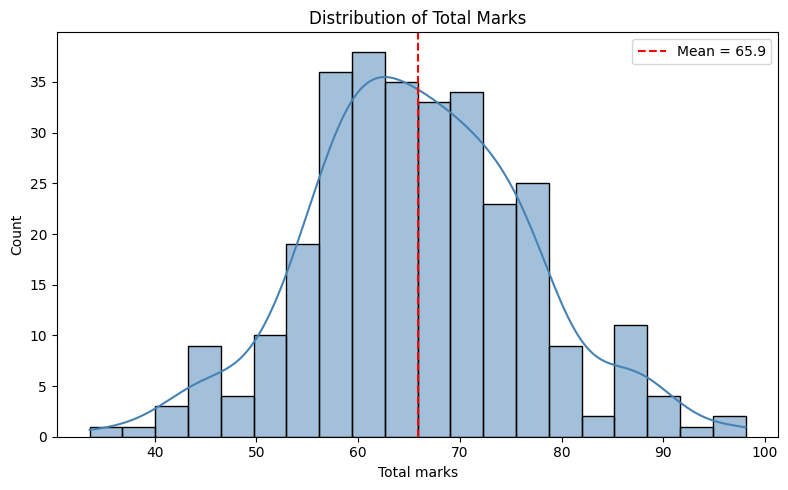

In [27]:
# Histogram of total marks
plt.figure(figsize=(8, 5))
sns.histplot(df["total"], bins=20, kde=True, color="steelblue")
plt.axvline(df["total"].mean(), color="red", linestyle="--", label=f"Mean = {df['total'].mean():.1f}")
plt.title("Distribution of Total Marks")
plt.xlabel("Total marks")
plt.legend()
plt.tight_layout()



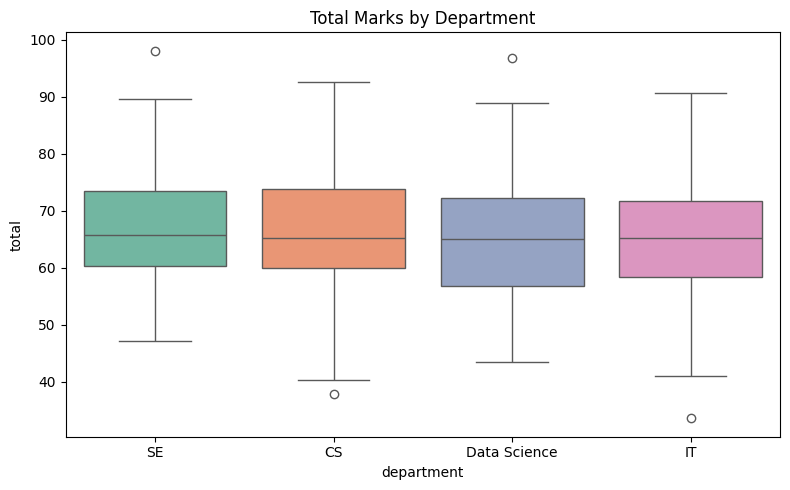

In [28]:
# Box plot of total marks by department
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="department", y="total", hue="department", palette="Set2", legend=False)
plt.title("Total Marks by Department")
plt.tight_layout()


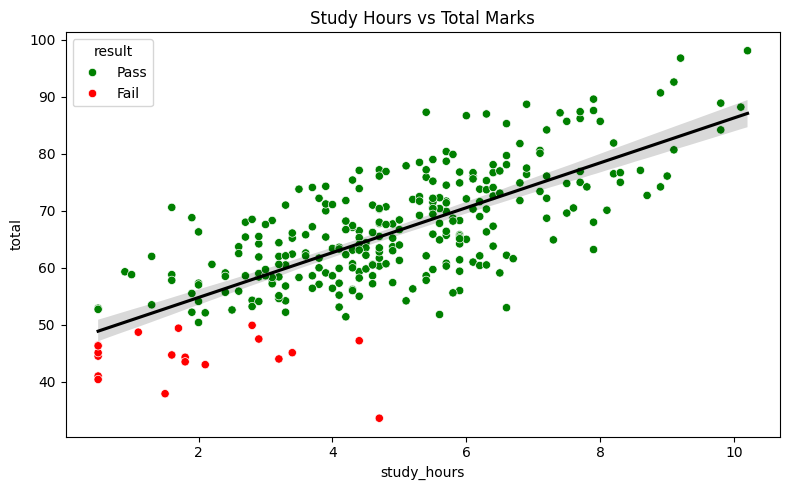

In [18]:
# Scatter plot, study hours vs total marks
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="study_hours", y="total", hue="result", palette={"Pass": "green", "Fail": "red"})
sns.regplot(data=df, x="study_hours", y="total", scatter=False, color="black")
plt.title("Study Hours vs Total Marks")
plt.tight_layout()

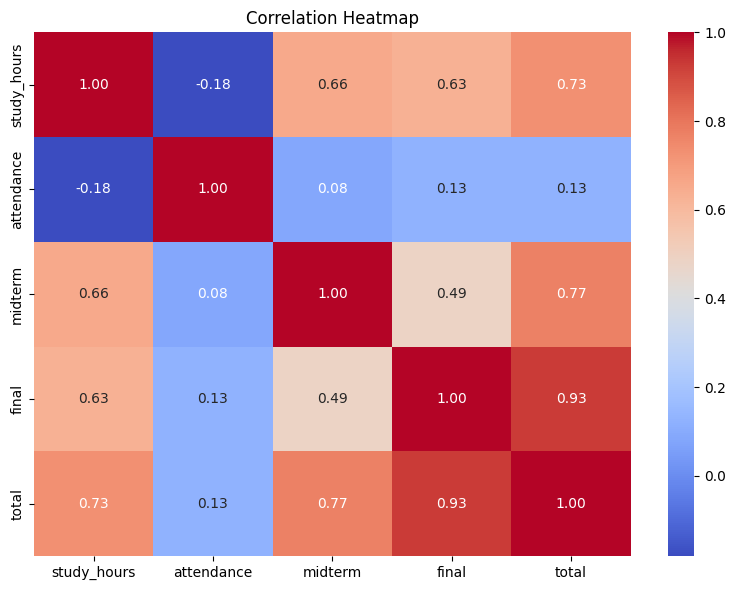

In [33]:
# Correlation heatmap
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()

